<a href="https://colab.research.google.com/github/makzjj/vision-tranformer-vs-resnet/blob/main/IE4483_Resnet50V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### IE4483 Mini Project (Option 2): Dogs vs. Cats (ResNet50V2)

Transfer learning with an ImageNet-pretrained ResNet50V2, using the same image operations and augmentation as the CNN notebook.

**How to run**
1. Place the dataset in `PROJECT_DIR/datasets/`, with `train/`, `val/` and `test/` folders. Set `PROJECT_DIR` in Section 1.
2. Change settings only in **Section 1 (Config)**.
3. Run all cells. After changing any setting, rerun from Section 1.

**Output:** `Submission.csv` is saved to `PROJECT_DIR`, along with a row in `results.csv`, the best checkpoint and the training-curve figure.

## 1. Setup and Configuration
Imports Libraries and define Settings.\
Change settings here, then rerun from this section.

In [ ]:
import sys
import time
import zipfile
import random
from pathlib import Path

import tensorflow as tf
import keras
from keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from IPython.display import Image, display

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Setup successful!")

I0000 00:00:1794201515.635682  145908 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794201515.683561  145908 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794201532.766499  145908 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python version: 3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:21:40) [GCC 14.3.0]
TensorFlow version: 2.22.0-rc0
Keras version: 3.16.0.dev2026101404
Setup successful!


In [ ]:
#Paths
PROJECT_DIR = Path("/usr1/home/s126mdg24_07/IE4483")
DATA_DIR = PROJECT_DIR / "datasets"
SUBMISSION_PATH = PROJECT_DIR / "Submission.csv"

#Seed
SEED = 41
tf.keras.utils.set_random_seed(SEED)

DETERMINISTIC = False
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()

#Data Split
TRAIN_PER_CLASS = 8000
VAL_PER_CLASS = 2500
TUNE_PER_CLASS = 2000

CLASS_NAMES = ["cat", "dog"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

#Image Size
IMAGE_SIZE = (224, 224)
SMALL_SIZE = (112, 112)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Choose: "baseline", "median", or "laplacian"
EXPERIMENT = "laplacian"
FILTER_PROBABILITY = 0.20
LAPLACIAN_STRENGTH = 0.20

USE_ROTATION = True
ROTATION_FACTOR = 0.05
USE_FLIPPING = True
USE_ZOOM = True
ZOOM_FACTOR = 0.15
USE_TRANSLATION = True
TRANSLATION_FACTOR = 0.10

# Keep False when comparing median against Laplacian.
USE_DOWNSCALING = False
DOWNSCALE_PROBABILITY = 0.20

# "cnn": [0, 1]
# "resnet50v2": [-1, 1]
NORMALIZATION = "resnet50v2"

Lists the contents of any ZIP archives in `PROJECT_DIR`, as a quick check that the dataset archive is present. Nothing is extracted.

In [ ]:
zip_files = sorted(PROJECT_DIR.glob("*.zip"))

if not zip_files:
    print("No ZIP files found. Check the file list above.")
else:
    for zip_path in zip_files:
        print(f"\nArchive: {zip_path.name}")

        with zipfile.ZipFile(zip_path, "r") as archive:
            files = [
                name for name in archive.namelist()
                if not name.endswith("/")
            ]

            print("Number of files:", len(files))
            print("First 10 file paths:")

            for name in files[:10]:
                print(" ", name)


Archive: datasets.zip
Number of files: 25502
First 10 file paths:
  datasets/.DS_Store
  __MACOSX/datasets/._.DS_Store
  datasets/test/63.jpg
  datasets/test/189.jpg
  datasets/test/77.jpg
  datasets/test/162.jpg
  datasets/test/176.jpg
  datasets/test/88.jpg
  datasets/test/348.jpg
  datasets/test/360.jpg


**Model hyperparameters.** Optimizer, early stopping and learning-rate settings, plus output folders. The VGG-style settings are carried over from the CNN notebook and are not used by this model.

In [ ]:
#Model Hyperparameters

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4          # AdamW weight decay (regularization)
EPOCHS = 50                  # Upper limit; early stopping usually ends sooner
EARLY_STOP_PATIENCE = 8      # Epochs without tuning-loss improvement before stopping
LR_PATIENCE = 3              # Epochs without improvement before halving the learning rate
MIN_LR = 1e-6
LABEL_SMOOTHING = 0.0        # e.g. 0.1 trains towards 0.05 / 0.95 instead of 0 / 1

#VGG-style Baseline
CONV_FILTERS = (32, 64, 128, 256)   # one block per entry; each block halves the image size
CONVS_PER_BLOCK = 2
USE_BATCHNORM = True
HEAD = "gap"                 # "gap" (GlobalAveragePooling) or "flatten"
DENSE_UNITS = 256            # hidden layer size, used only by the "flatten" head
DROPOUT = 0.4
KERNEL_INIT = "he_normal"    # "he_normal" or "glorot_uniform" (Keras default)

#Speed: float16 compute on GPU (about 2x faster); ignored on CPU
MIXED_PRECISION = True

#Outputs saved to Drive
RESULTS_PATH = PROJECT_DIR / "results.csv"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
FIGURE_DIR = PROJECT_DIR / "figures"

if MIXED_PRECISION and tf.config.list_physical_devices("GPU"):
    keras.mixed_precision.set_global_policy("mixed_float16")

else:
    keras.mixed_precision.set_global_policy("float32")
print("Precision policy:", keras.mixed_precision.global_policy().name)

Precision policy: mixed_float16


In [ ]:
#GPU Availability
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

if gpus:
  print("GPU is available for training.")
else:
  print("No GPU detected. CPU can run code, but slower")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:3', device_type='GPU')]
GPU is available for training.


## 2. Check data
Confirms the dataset folder exists and lists its contents. The dataset is read directly from `DATA_DIR`, so no extraction step is needed.

In [ ]:
print("Dataset location:", DATA_DIR)
print("Contents:", [p.name for p in DATA_DIR.iterdir()])

Dataset location: /usr1/home/s126mdg24_07/IE4483/datasets
Contents: ['val', 'test', 'train']


## 3. Select files
Checks the dataset counts against the brief, then draws a seeded random subset of images per class:
- **Train** (8,000 per class) and **Tune** (2,000 per class) are drawn together from `train/`, so they never overlap. The tuning set drives early stopping and learning-rate reduction.
- **Val** (2,500 per class) comes from the official `val/` folder and is held out until the final evaluation.

Labels are assigned from the folder names (cat = 0, dog = 1), and test files are sorted by numeric ID for the submission.

In [ ]:
def image_files(folder):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

for split in ["train", "val"]:
    for name in CLASS_NAMES:
        folder = DATA_DIR / split / name

        if not folder.is_dir():
            raise FileNotFoundError(f"Missing folder: {folder}")

        print(f"{split}/{name}: {len(image_files(folder))} images")

print("Test images:", len(image_files(DATA_DIR / "test")))

train/cat: 10000 images
train/dog: 10000 images
val/cat: 2500 images
val/dog: 2500 images
Test images: 500


In [ ]:
rng = random.Random(SEED)
selected_files = {}

for name in CLASS_NAMES:
    # Train and tuning images are drawn together from train/, so they never overlap.
    files = image_files(DATA_DIR / "train" / name)
    needed = TRAIN_PER_CLASS + TUNE_PER_CLASS
    if len(files) < needed:
        raise ValueError(f"train/{name} has only {len(files)} images; {needed} requested.")
    picked = rng.sample(files, needed)
    selected_files[("train", name)] = picked[:TRAIN_PER_CLASS]
    selected_files[("tune", name)] = picked[TRAIN_PER_CLASS:]

    files = image_files(DATA_DIR / "val" / name)
    if len(files) < VAL_PER_CLASS:
        raise ValueError(f"val/{name} has only {len(files)} images; {VAL_PER_CLASS} requested.")
    selected_files[("val", name)] = rng.sample(files, VAL_PER_CLASS)

def paths_and_labels(split):
    paths, labels = [], []
    for i, name in enumerate(CLASS_NAMES):
        files = selected_files[(split, name)]
        paths.extend(files)
        labels.extend([i] * len(files))
    return paths, labels

train_paths, train_labels = paths_and_labels("train")
tune_paths, tune_labels = paths_and_labels("tune")
val_paths, val_labels = paths_and_labels("val")

test_paths = sorted(image_files(DATA_DIR / "test"), key=lambda p: int(p.stem))
test_ids = [int(p.stem) for p in test_paths]

print(f"Selected -> train: {len(train_paths)}, tune: {len(tune_paths)}, "
      f"val: {len(val_paths)}, test: {len(test_paths)}")

Selected -> train: 16000, tune: 4000, val: 5000, test: 500


## 4. Image operations
Building blocks used by the pipelines:
- Image Loading and Resizing
- Simulated Low-Resolution Downscaling
- Median Filtering
- Laplacian Sharpening
- Normalization

All operations work on pixel values in [0, 255]; normalization runs last.

In [ ]:
#Decode format to RGB and resize to IMAGE_SIZE (float32, 0 - 255)
def load_rgb_image(path):
    image = tf.io.decode_image(
        tf.io.read_file(path),
        channels=3,
        expand_animations=False
        )

    image.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(image, tf.float32),
        IMAGE_SIZE,
        method="bilinear",
        antialias=True
        )

#Simulate low-res photo, then upsample back
def downscale_image(image):
    smaller = tf.image.resize(image, SMALL_SIZE, method="bilinear", antialias=True)
    return tf.image.resize(smaller, IMAGE_SIZE, method="bilinear")

def median_numpy(image):
    return median_filter(
        np.asarray(image, dtype=np.float32),
        size=(3, 3, 1),  # Filter each RGB channel separately.
        mode="reflect"
    ).astype(np.float32)

def median_image(image):
    result = tf.numpy_function(
        median_numpy,
        [image],
        Tout=tf.float32
    )
    result.set_shape([*IMAGE_SIZE, 3])
    return result

def laplacian_sharpen(image, strength=0.20):
    kernel = tf.constant([[0.0,  1.0, 0.0],
                          [1.0, -4.0, 1.0],
                          [0.0,  1.0, 0.0]], dtype=tf.float32)

    kernel = tf.reshape(kernel, [3, 3, 1, 1])
    kernel = tf.tile(kernel, [1, 1, 3, 1])

    padded = tf.pad(image[tf.newaxis, ...],
                   [[0, 0], [1, 1], [1, 1], [0, 0]],
                   mode="REFLECT")

    laplacian = tf.nn.depthwise_conv2d(
        padded,
        kernel,
        strides=[1, 1, 1, 1],
        padding="VALID")[0]

    return tf.clip_by_value(image - strength * laplacian, 0.0, 255.0)

def normalize_image(image, mode):
    image = tf.clip_by_value(image, 0.0, 255.0)
    if mode == "cnn":
        return image / 255.0
    if mode == "resnet50v2":
        return image / 127.5 - 1.0
    raise ValueError("Choose 'cnn' or 'resnet50v2'.")

def denormalize_for_display(image, mode):
    return (image + 1.0) / 2.0 if mode == "resnet50v2" else image

## 5. Train and eval pipelines
Builds the `tf.data` input pipelines. Training images are cached, shuffled and randomly augmented. Tuning, validation and test images are only resized, cached and normalized, so evaluation uses unaltered images.

- **Train:** load → resize → cache → shuffle → (downscale) → (median or Laplacian) → batch → flip → rotate → zoom → translate → normalize
- **Tune/Val/Test:** load → resize → cache → normalize

With `NORMALIZATION = "resnet50v2"`, pixels are scaled to [-1, 1], the range ResNet50V2 was pretrained with.

In [ ]:
def build_training_dataset(
    paths,
    labels,
    experiment="baseline",
    flipping=True,
    rotation=True,
    rotation_factor=0.05,
    zoom=False,
    zoom_factor=0.15,
    translation=False,
    translation_factor=0.10,
    downscaling=False,
    downscale_probability=0.20,
    filter_probability=0.20,
    laplacian_strength=0.20,
    normalization="resnet50v2",
    seed=41,
    debug=False,
):

    if experiment not in {"baseline", "median", "laplacian"}:
        raise ValueError("Choose 'baseline', 'median', or 'laplacian'.")

    label_array = np.asarray(labels, dtype=np.float32).reshape(-1)
    if len(paths) == 0 or len(paths) != len(label_array):
        raise ValueError("Check your image paths and labels.")

    for probability in [downscale_probability,filter_probability]:
        if not 0.0 <= probability <= 1.0:
            raise ValueError("Probabilities must be between 0 and 1.")

    if laplacian_strength < 0:
        raise ValueError("Sharpening strength must be nonnegative.")

    if not np.isin(label_array, [0, 1]).all():
        raise ValueError("Labels must be 0 or 1.")

    downscale_rng = tf.random.Generator.from_seed(seed + 2)
    filter_rng = tf.random.Generator.from_seed(seed + 3)

    #Geometric Augmentation, per batch
    augmentation_layers = []

    if flipping:
        augmentation_layers.append(
            layers.RandomFlip("horizontal", seed=seed))

    if rotation:
        augmentation_layers.append(
            layers.RandomRotation(
                factor=rotation_factor,
                fill_mode="reflect",
                seed=seed + 1
            )
        )

    if zoom:
        augmentation_layers.append(
            layers.RandomZoom(
                (-zoom_factor, zoom_factor),
                fill_mode="reflect",
                seed=seed + 4)
            )

    if translation:
        augmentation_layers.append(
            layers.RandomTranslation(
                translation_factor,
                translation_factor,
                fill_mode="reflect",
                seed=seed + 5)
            )

    augmentation = (
        tf.keras.Sequential(augmentation_layers)
        if augmentation_layers else None
    )

    def load_labeled_image(path, label):
        image = load_rgb_image(path)
        label = tf.reshape(tf.cast(label, tf.float32), [1])
        return image, label

    def random_image_processing(image, label):
        downscale_applied = tf.constant(False)
        filter_applied = tf.constant(False)

        if downscaling:
            downscale_applied = (
                downscale_rng.uniform(shape=())
                < downscale_probability
            )

            image = tf.cond(
                downscale_applied,
                lambda: downscale_image(image),
                lambda: tf.identity(image)
            )

        if experiment != "baseline":
            filter_applied = filter_rng.uniform(shape=()) < filter_probability

            if experiment == "median":
                apply_filter = lambda: median_image(image)

            else:
                apply_filter = lambda: laplacian_sharpen(image, laplacian_strength)

            image = tf.cond(filter_applied, apply_filter, lambda: image)

        image.set_shape([*IMAGE_SIZE, 3])
        return image, label, downscale_applied, filter_applied

    def augment_batch(images, labels, downscaled, filtered):
        return (
            augmentation(images, training=True),
            labels,
            downscaled,
            filtered
        )

    def normalize_batch(images, labels, downscaled, filtered):
        return (
            normalize_image(images, normalization),
            labels,
            downscaled,
            filtered
        )

    dataset = tf.data.Dataset.from_tensor_slices((
        [str(path) for path in paths],
        label_array
    ))

    dataset = dataset.map(
        load_labeled_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.cache()


    dataset = dataset.shuffle(
        buffer_size=len(paths),
        seed=seed,
        reshuffle_each_iteration=True
    )

    # Independent random decisions for each image.
    dataset = dataset.map(
        random_image_processing,
        num_parallel_calls=1
    )

    dataset = dataset.batch(BATCH_SIZE)

    if augmentation is not None:
        dataset = dataset.map(
            augment_batch,
            num_parallel_calls=1
        )

    dataset = dataset.map(
        normalize_batch,
        num_parallel_calls=AUTOTUNE
    )

    if not debug:
        # model.fit() receives only images and labels.
        dataset = dataset.map(
            lambda images, labels, downscaled, filtered: (
                images, labels
            ),
            num_parallel_calls=AUTOTUNE
        )
    return dataset.prefetch(AUTOTUNE)

#Validation Dataset (No Shuffling [IDs strict] & No Augmentation)
def build_eval_dataset(paths, labels=None, normalization="cnn"):
    images = tf.data.Dataset.from_tensor_slices([str(p) for p in paths])
    images = images.map(load_rgb_image, num_parallel_calls=AUTOTUNE).cache()
    images = images.map(lambda x: normalize_image(x, normalization),
                        num_parallel_calls=AUTOTUNE)

    if labels is None:
        dataset = images
    else:
        label_ds = tf.data.Dataset.from_tensor_slices(
            np.asarray(labels, dtype=np.float32).reshape(-1, 1))
        dataset = tf.data.Dataset.zip((images, label_ds))

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [ ]:
TRAIN_SETTINGS = dict(
    experiment=EXPERIMENT,
    rotation=USE_ROTATION,
    flipping=USE_FLIPPING,
    rotation_factor=ROTATION_FACTOR,
    zoom=USE_ZOOM,
    zoom_factor=ZOOM_FACTOR,
    translation=USE_TRANSLATION,
    translation_factor=TRANSLATION_FACTOR,
    downscaling=USE_DOWNSCALING,
    downscale_probability=DOWNSCALE_PROBABILITY,
    filter_probability=FILTER_PROBABILITY,
    laplacian_strength=LAPLACIAN_STRENGTH,
    normalization=NORMALIZATION,
    seed=SEED
)

train_ready = build_training_dataset(train_paths, train_labels, **TRAIN_SETTINGS)
tune_ready = build_eval_dataset(tune_paths, tune_labels, normalization=NORMALIZATION)
val_ready = build_eval_dataset(val_paths, val_labels, normalization=NORMALIZATION)
test_ready = build_eval_dataset(test_paths, normalization=NORMALIZATION)

print("Experiment:", EXPERIMENT, "| normalization:", NORMALIZATION)
print("train batch spec:", train_ready.element_spec)
print("tune batch spec: ", tune_ready.element_spec)
print("val batch spec:  ", val_ready.element_spec)
print("test batch spec: ", test_ready.element_spec)

I0000 00:00:1794201549.177973  145908 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14658 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:19:00.0, compute capability: 8.6
I0000 00:00:1794201549.179938  145908 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 22309 MB memory:  -> device: 1, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:1a:00.0, compute capability: 8.6
I0000 00:00:1794201549.181672  145908 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 22309 MB memory:  -> device: 2, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:67:00.0, compute capability: 8.6
I0000 00:00:1794201549.183498  145908 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 22284 MB memory:  -> device: 3, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:68:00.0, compute capability: 8.6


Experiment: laplacian | normalization: resnet50v2
train batch spec: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float16, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
tune batch spec:  (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
val batch spec:   (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
test batch spec:  TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)


## 6. Preview
**Visual checks:** raw resized training images & a batch from the augmented training pipeline labelled with which filters and downscaling were applied.

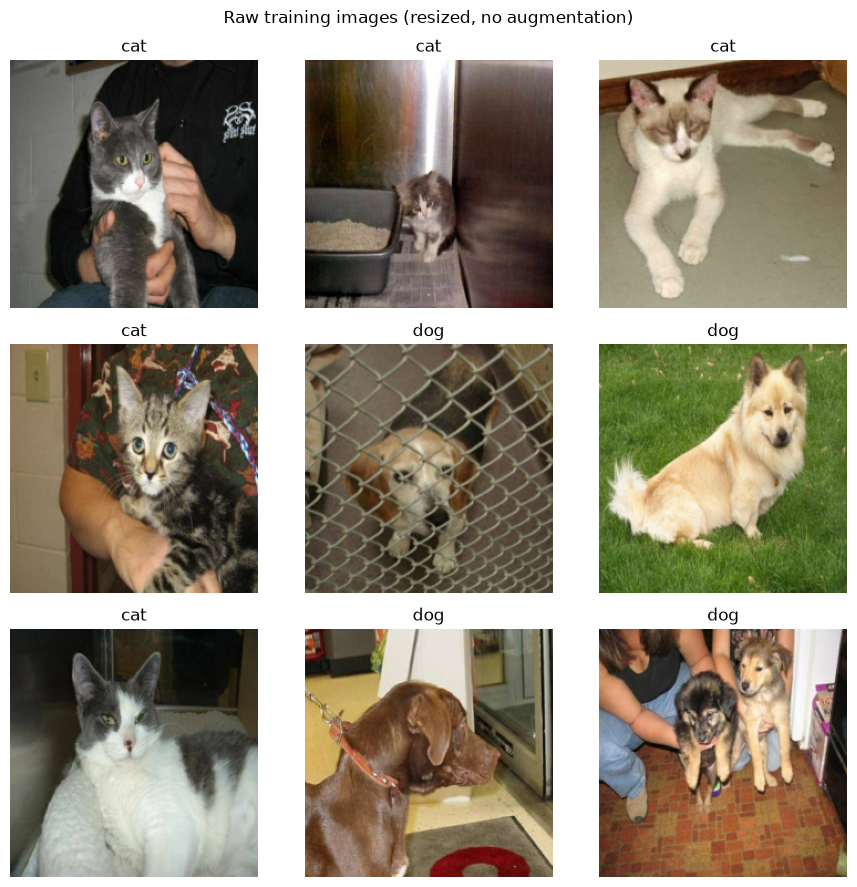

In [ ]:
sample_idx = random.Random(SEED).sample(range(len(train_paths)), 9)
sample_paths = [train_paths[i] for i in sample_idx]
sample_labels = [train_labels[i] for i in sample_idx]

raw_images = next(iter(build_eval_dataset(sample_paths, normalization="cnn")))

plt.figure(figsize=(9, 9))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(raw_images[i].numpy())
    plt.title(CLASS_NAMES[sample_labels[i]])
    plt.axis("off")
plt.suptitle("Raw training images (resized, no augmentation)")
plt.tight_layout()
plt.show()

E0000 00:00:1794201553.100519  145908 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


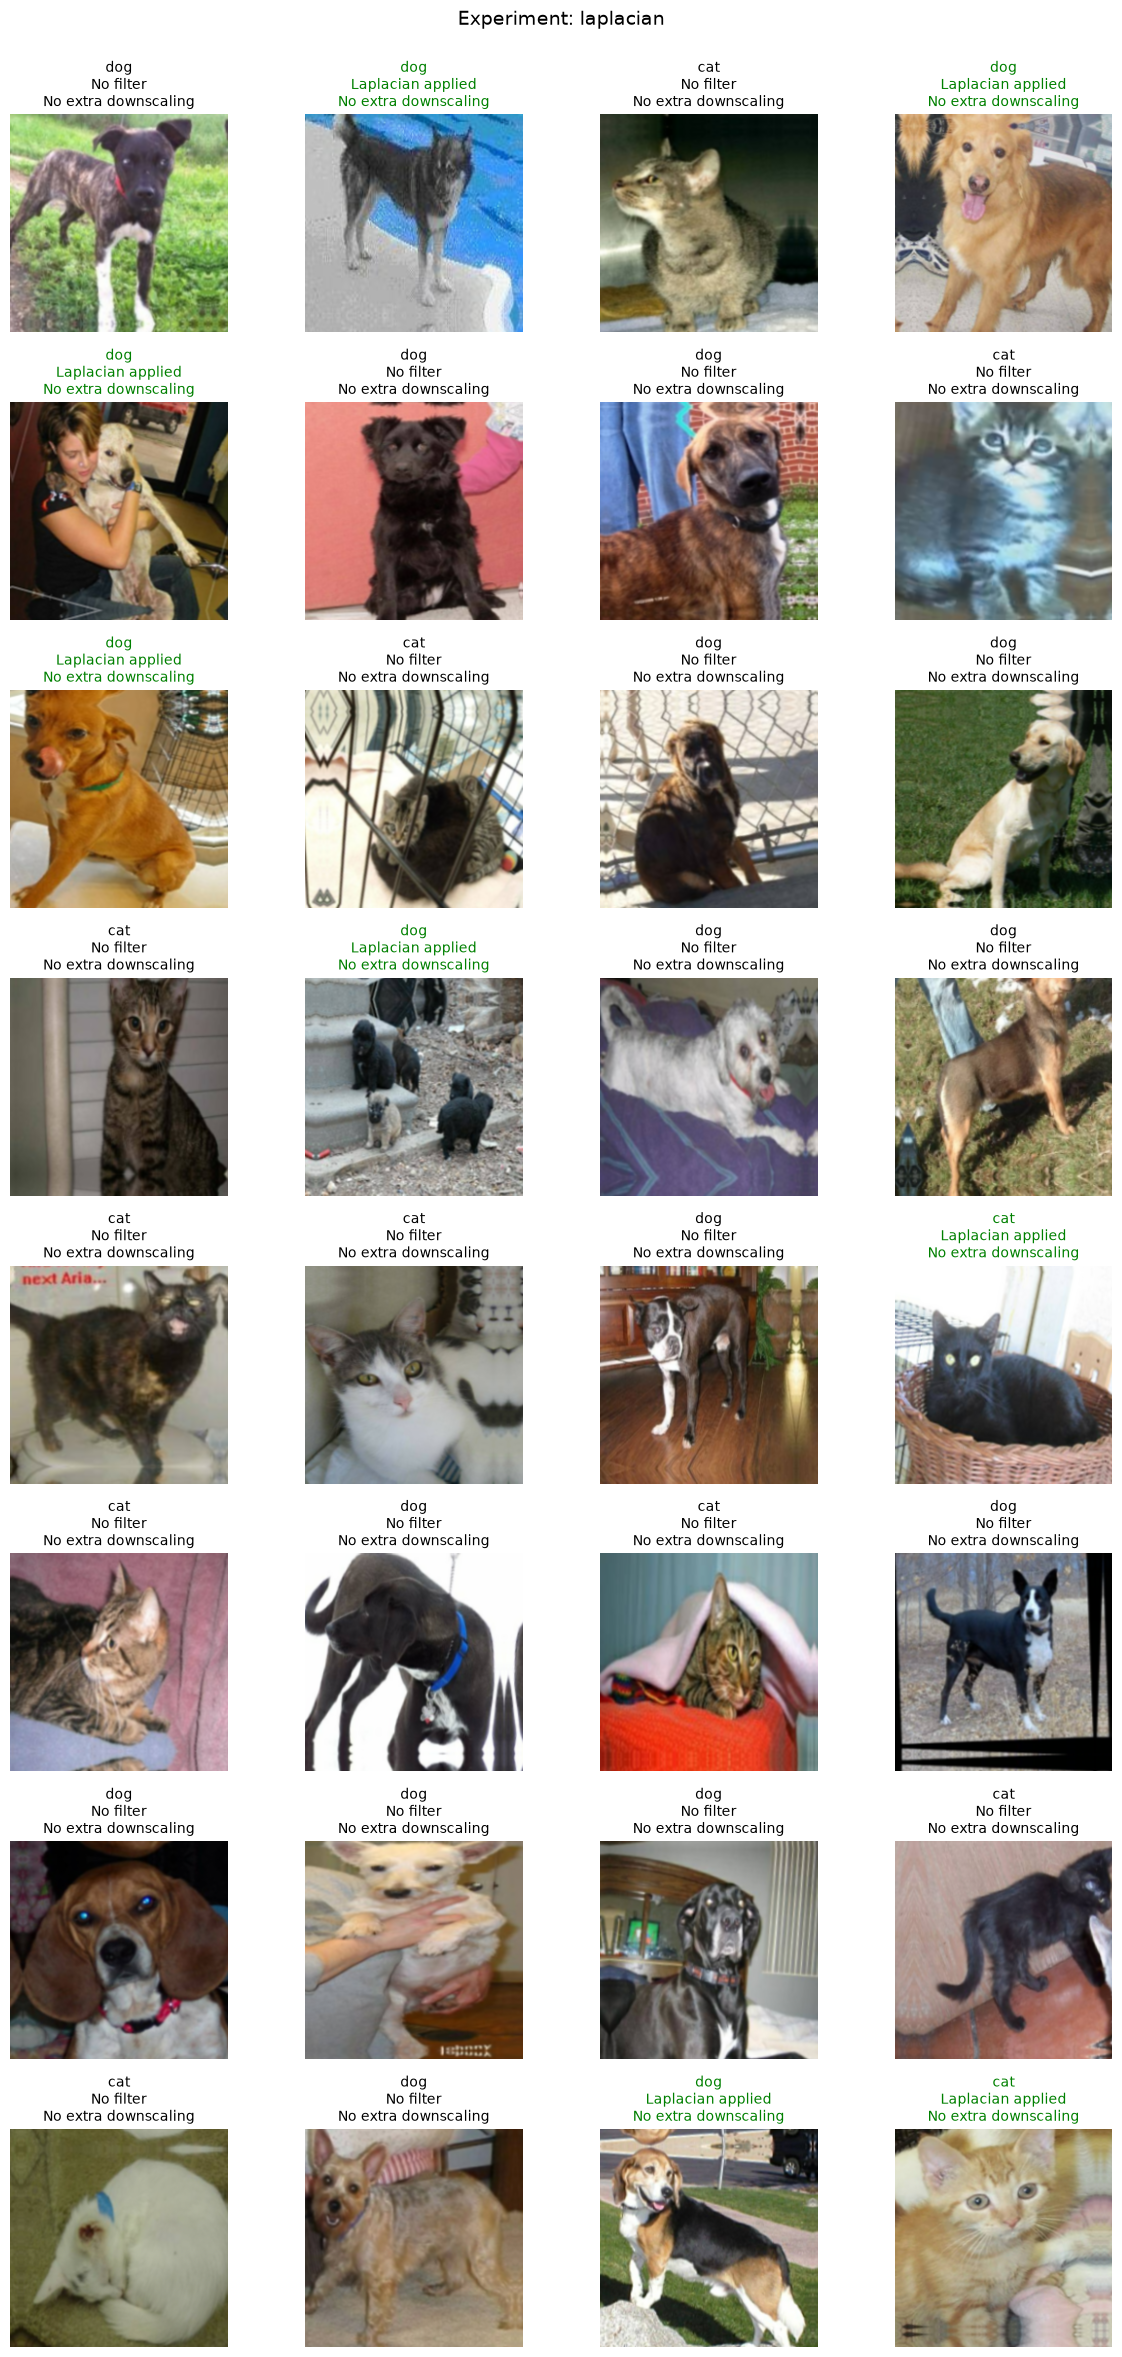

Experiment: laplacian
Filter applied: 8/32 images
Extra downscaling: 0/32 images
Image batch shape: (32, 224, 224, 3)


In [ ]:
# Separate preview pipeline with transformation flags
preview_ds = build_training_dataset(train_paths, train_labels, **TRAIN_SETTINGS, debug=True)
images, labels, downscaled, filtered = next(iter(preview_ds))
tf.debugging.assert_all_finite(images, "Images contain invalid values.")

filter_name = {
    "baseline": "Filter",
    "median": "Median",
    "laplacian": "Laplacian"
}[EXPERIMENT]

number = int(images.shape[0])
columns = 4
rows = (number + columns - 1) // columns

fig, axes = plt.subplots(
    rows,
    columns,
    figsize=(12, rows * 3),
    squeeze=False
)

for ax in axes.flat:
    ax.axis("off")

for i in range(number):
    image = denormalize_for_display(images[i].numpy(), NORMALIZATION)
    was_filtered = bool(filtered[i].numpy())
    was_downscaled = bool(downscaled[i].numpy())

    filter_status = (
        f"{filter_name} applied"
        if was_filtered else "No filter"
    )

    downscale_status = (
        "Extra downscaling"
        if was_downscaled else "No extra downscaling"
    )

    label = CLASS_NAMES[int(labels[i, 0].numpy())]

    axes.flat[i].imshow(np.clip(image, 0, 1))
    axes.flat[i].set_title(
        f"{label}\n{filter_status}\n{downscale_status}",
        color="green" if was_filtered else "black",
        fontsize=10
    )

fig.suptitle(f"Experiment: {EXPERIMENT}", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

filter_count = int(
    tf.reduce_sum(tf.cast(filtered, tf.int32)).numpy()
)

downscale_count = int(
    tf.reduce_sum(tf.cast(downscaled, tf.int32)).numpy()
)

print("Experiment:", EXPERIMENT)
print(f"Filter applied: {filter_count}/{number} images")
print(f"Extra downscaling: {downscale_count}/{number} images")
print("Image batch shape:", images.shape)

## 7. Models and submission
Model definition, training and evaluation. `write_submission` predicts the test set and writes `Submission.csv` with IDs in numeric order (1 = dog, 0 = cat).

In [ ]:
def write_submission(model, path=SUBMISSION_PATH, threshold=0.5):
    """Predict the test set and write submission.csv (1 = dog, 0 = cat)."""
    probabilities = model.predict(test_ready, verbose=0).reshape(-1)
    predictions = (probabilities >= threshold).astype(int)

    if len(predictions) != len(test_ids):
        raise ValueError("Prediction count does not match the number of test images.")

    with open(path, "w") as f:
        f.write("id,label\n")
        for image_id, label in zip(test_ids, predictions):
            f.write(f"{image_id},{label}\n")

    print(f"Wrote {len(predictions)} rows to {path} "
          f"({predictions.sum()} dogs, {len(predictions) - predictions.sum()} cats)")
    return probabilities

### 7.1 Training utilities
Shared by every model, so each experiment is one function call.

- `run_experiment` seeds everything, builds a fresh training pipeline, trains with early stopping, and appends the result to `results.csv`.
- The **tuning set** is passed as `validation_data`, so Keras labels its metrics `val_loss` / `val_accuracy` / `val_auc`. Early stopping and learning-rate halving both monitor this tuning loss.
- The **held-out validation set** is evaluated once at the end when `evaluate_val=True`, and logged as `val_acc` / `val_auc` in `results.csv`.
- Training accuracy is measured with augmentation and dropout active, so it can sit slightly below tuning accuracy early in training. This is expected.

In [ ]:
for folder in [CHECKPOINT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

INPUT_SHAPE = (*IMAGE_SIZE, 3)


def compile_model(model, learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
                  label_smoothing=LABEL_SMOOTHING):
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=weight_decay),
        loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing),
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")],
    )
    return model


def make_callbacks(checkpoint_name):
    return [
        # Stop when tuning loss stops improving, and keep the best epoch's weights.
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=EARLY_STOP_PATIENCE,
            restore_best_weights=True, verbose=1),
        # Halve the learning rate when progress stalls.
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=LR_PATIENCE,
            min_lr=MIN_LR, verbose=1),
        # Save the best model to Drive, so it survives a Colab disconnect.
        keras.callbacks.ModelCheckpoint(
            str(CHECKPOINT_DIR / f"{checkpoint_name}.keras"),
            monitor="val_loss", save_best_only=True),
    ]


def log_result(record, path=RESULTS_PATH):
    row = pd.DataFrame([record])
    if path.exists():
        row = pd.concat([pd.read_csv(path), row], ignore_index=True)
    row.to_csv(path, index=False)


def run_experiment(build_model, run_name, seed=SEED, train_settings=None,
                   evaluate_val=False, epochs=EPOCHS, verbose=1, **compile_kwargs):
    """Train one model and log the result.

    build_model:    function with no arguments that returns an uncompiled model,
                    e.g. build_vgg_baseline or lambda: build_vgg_baseline(head="flatten").
    run_name:       name for this configuration; repeat it across seeds so results group.
    train_settings: augmentation settings; defaults to TRAIN_SETTINGS.
    evaluate_val:   also evaluate on the official val set (final runs only).
    compile_kwargs: learning_rate, weight_decay or label_smoothing overrides.
    """
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)   # weight initialization, dropout, shuffling

    settings = dict(TRAIN_SETTINGS if train_settings is None else train_settings, seed=seed)
    if settings["normalization"] != NORMALIZATION:
        raise ValueError("train_settings normalization must match NORMALIZATION "
                         "(the tuning/val/test pipelines use NORMALIZATION).")
    train_ds = build_training_dataset(train_paths, train_labels, **settings)

    model = compile_model(build_model(), **compile_kwargs)

    start = time.time()
    history = model.fit(
        train_ds,
        validation_data=tune_ready,
        epochs=epochs,
        callbacks=make_callbacks(f"{run_name}_s{seed}"),
        shuffle=False,   # train_ds already reshuffles every epoch
        verbose=verbose,
    )
    train_minutes = (time.time() - start) / 60

    tune = model.evaluate(tune_ready, verbose=0, return_dict=True)
    val = model.evaluate(val_ready, verbose=0, return_dict=True) if evaluate_val else {}

    record = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M"),
        "run_name": run_name,
        "seed": seed,
        "model": model.name,
        "params": model.count_params(),
        "image_size": IMAGE_SIZE[0],
        "train_images": len(train_paths),
        "experiment": settings["experiment"],
        "learning_rate": compile_kwargs.get("learning_rate", LEARNING_RATE),
        "weight_decay": compile_kwargs.get("weight_decay", WEIGHT_DECAY),
        "label_smoothing": compile_kwargs.get("label_smoothing", LABEL_SMOOTHING),
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
        "train_minutes": round(train_minutes, 2),
        "tune_loss": round(tune["loss"], 4),
        "tune_acc": round(tune["accuracy"], 4),
        "tune_auc": round(tune["auc"], 4),
        "val_loss": round(val["loss"], 4) if val else None,
        "val_acc": round(val["accuracy"], 4) if val else None,
        "val_auc": round(val["auc"], 4) if val else None,
        "augmentation": str({k: v for k, v in settings.items() if k != "seed"}),
    }
    log_result(record)
    print(f"\n{run_name} (seed {seed}): tune acc {record['tune_acc']:.4f}"
          + (f", val acc {record['val_acc']:.4f}" if val else "")
          + f", best epoch {record['best_epoch']}, {record['train_minutes']} min")
    return model, history, record


def plot_history(history, title, save=True):
    """Training vs tuning curves for loss and accuracy."""
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, label in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(epochs, h[key], label="train")
        ax.plot(epochs, h[f"val_{key}"], label="tuning")
        ax.axvline(best, color="grey", linestyle="--", label=f"best epoch ({best})")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if save:
        fig.savefig(FIGURE_DIR / f"{title}.png", dpi=150)
    plt.show()


def summarize_results(path=RESULTS_PATH, metrics=("tune_acc", "val_acc")):
    """Mean, std and run count per configuration (run_name)."""
    df = pd.read_csv(path)
    present = [m for m in metrics if m in df and df[m].notna().any()]
    return df.groupby("run_name")[present].agg(["mean", "std", "count"]).round(4)

### 7.2 ResNet50V2 (transfer learning)
- **Backbone:** ResNet50V2 pretrained on ImageNet, with its classifier removed (`include_top=False`). The backbone is **frozen** (`base_model.trainable = False`), so it acts as a fixed feature extractor. Calling it with `training=False` keeps its BatchNorm layers in inference mode.
- **Head:** GlobalAveragePooling → Dropout (0.2) → one sigmoid unit giving P(dog), trained with binary cross-entropy.
- **Trainable parameters:** only the head's 2,049 weights train; the backbone's 23.6M stay at their ImageNet values.

In [ ]:
def build_resnet50v2():
    base_model = tf.keras.applications.ResNet50V2(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMAGE_SIZE, 3),
    )

    base_model.trainable = False

    inputs = layers.Input(
        shape=(*IMAGE_SIZE, 3),
        name="image",
    )

    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    return tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="resnet50v2",
    )


resnet50v2 = build_resnet50v2()
resnet50v2.summary()

Model: "resnet50v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,566,849 (89.90 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

### 7.3 Train ResNet50V2
One run with the settings from Section 1. The best epoch's weights are restored, scored on the tuning and held-out validation sets, and logged to `results.csv`. The next cell plots training vs tuning curves and saves them to `figures/`.

In [ ]:
resnet_model, resnet_history, resnet_record = run_experiment(
    build_model=build_resnet50v2,
    run_name="resnet50v2",
    seed=SEED,
    evaluate_val=True,
)

Epoch 1/50


I0000 00:00:1794201570.581703  145908 service.cc:154] XLA service 0x5b32aaab8d60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794201570.581726  145908 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3090, Compute Capability 8.6 (Driver: 13.0.0[580.173.2]; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1794201570.581730  145908 service.cc:170]   StreamExecutor [1]: NVIDIA GeForce RTX 3090, Compute Capability 8.6 (Driver: 13.0.0[580.173.2]; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1794201570.581733  145908 service.cc:170]   StreamExecutor [2]: NVIDIA GeForce RTX 3090, Compute Capability 8.6 (Driver: 13.0.0[580.173.2]; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1794201570.581735  145908 service.cc:170]   StreamExecutor [3]: NVIDIA GeForce RTX 3090, Compute Capability 8.6 (Driver: 13.0.0[580.173.2]; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1794201570.644931  1459

  5/500 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8063 - auc: 0.8604 - loss: 0.4754 

I0000 00:00:1794201580.679970  145908 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1794201580.753117  145908 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1794201567911796273 in buffer 'PrefetchDataset/_30' sat unconsumed for 12.5069 seconds!


500/500 ━━━━━━━━━━━━━━━━━━━━ 196s 360ms/step - accuracy: 0.9714 - auc: 0.9962 - loss: 0.0778 - val_accuracy: 0.9845 - val_auc: 0.9982 - val_loss: 0.0471 - learning_rate: 0.0010
Epoch 2/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 184s 368ms/step - accuracy: 0.9806 - auc: 0.9979 - loss: 0.0535 - val_accuracy: 0.9893 - val_auc: 0.9988 - val_loss: 0.0326 - learning_rate: 0.0010
Epoch 3/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 187s 373ms/step - accuracy: 0.9827 - auc: 0.9983 - loss: 0.0459 - val_accuracy: 0.9898 - val_auc: 0.9985 - val_loss: 0.0321 - learning_rate: 0.0010
Epoch 4/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 188s 375ms/step - accuracy: 0.9832 - auc: 0.9985 - loss: 0.0435 - val_accuracy: 0.9902 - val_auc: 0.9983 - val_loss: 0.0320 - learning_rate: 0.0010
Epoch 5/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 183s 366ms/step - accuracy: 0.9828 - auc: 0.9985 - loss: 0.0437 - val_accuracy: 0.9898 - val_auc: 0.9988 - val_loss: 0.0316 - learning_rate: 0.0010
Epoch 6/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 186s 372ms/step - accuracy: 0.9

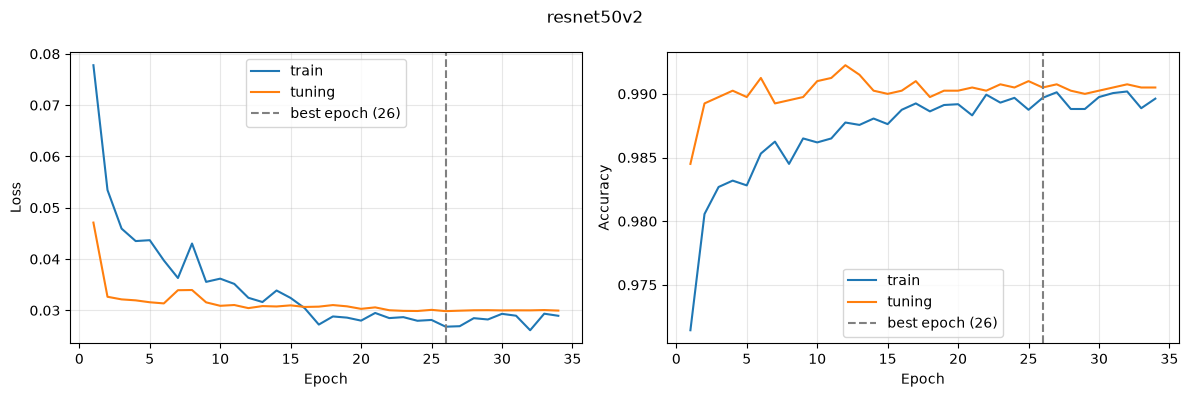

In [ ]:
plot_history(
    resnet_history,
    title="resnet50v2",
)

### 7.4 Write submission
Reloads the best checkpoint from disk (so this works after a restart) and writes `Submission.csv` for the test set, using a 0.5 threshold on P(dog).

In [ ]:
resnet_model = tf.keras.models.load_model(
    CHECKPOINT_DIR / f"resnet50v2_s{SEED}.keras"
)

dog_probabilities = write_submission(
    resnet_model,
    path=SUBMISSION_PATH,
    threshold=0.5,
)

Wrote 500 rows to /usr1/home/s126mdg24_07/IE4483/Submission.csv (262 dogs, 238 cats)


### 7.5 Model and training configuration
Prints a reference of the architecture and training setup for the report: input and output shapes, total / trainable / non-trainable parameter counts, loss, metrics, optimizer settings, distribution strategy and a per-layer table.

This inspects the `resnet50v2` model built in Section 7.2, which has the same architecture and settings as the trained model but not its trained weights. It reports the configuration, not results.

In [ ]:
print("=== MODEL ===")
print("Name:", resnet50v2.name)
print("Input shape:", resnet50v2.input_shape)
print("Output shape:", resnet50v2.output_shape)
print("Total parameters:", resnet50v2.count_params())
print("Trainable parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in resnet50v2.trainable_weights
))
print("Non-trainable parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in resnet50v2.non_trainable_weights
))

print("\n=== MODEL SUMMARY ===")
resnet50v2.summary()

compile_model(resnet50v2)

print("\n=== COMPILE SETTINGS ===")
print("Loss:", resnet50v2.loss)
print("Metrics:", resnet50v2.metrics)

optimizer = resnet50v2.optimizer
print("Optimizer:", optimizer.__class__.__name__)
print("Optimizer configuration:")
for key, value in optimizer.get_config().items():
    print(f"  {key}: {value}")

print("\n=== TRAINING STRATEGY ===")
print(tf.distribute.get_strategy())

print("\n=== LAYERS ===")
for index, layer in enumerate(resnet50v2.layers):
    print(
        f"{index:3d} | "
        f"{layer.name:35s} | "
        f"{layer.__class__.__name__:25s} | "
        f"trainable={layer.trainable} | "
        f"params={layer.count_params()}"
    )

=== MODEL ===
Name: resnet50v2
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 23566849
Trainable parameters: 2049
Non-trainable parameters: 23564800

=== MODEL SUMMARY ===


Model: "resnet50v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,566,849 (89.90 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,564,800 (89.89 MB)


=== COMPILE SETTINGS ===
Loss: <LossFunctionWrapper(<function binary_crossentropy at 0x78896df0d2d0>, kwargs={'from_logits': False, 'label_smoothing': 0.0, 'axis': -1})>
Metrics: [<Mean name=loss>, <CompileMetrics name=compile_metrics>]
Optimizer: LossScaleOptimizer
Optimizer configuration:
  name: loss_scale_optimizer
  inner_optimizer: {'module': 'keras.optimizers', 'class_name': 'AdamW', 'config': {'name': 'adam_w_1', 'learning_rate': 0.0010000000474974513, 'weight_decay': 0.0001, 'clipnorm': None, 'global_clipnorm': None, 'clipvalue': None, 'use_ema': False, 'ema_momentum': 0.99, 'ema_overwrite_frequency': None, 'loss_scale_factor': None, 'gradient_accumulation_steps': None, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07, 'amsgrad': False}, 'registered_name': None}
  initial_scale: 32768.0
  dynamic_growth_steps: 2000

=== TRAINING STRATEGY ===

=== LAYERS ===
  0 | image                               | InputLayer                | trainable=True | params=0
  1 | resnet50v2      